# 딥러닝 ② FOCUS ON TRANSFORMER

## 1. 인트로  
  
### 1-1. RNN 한계와 어텐션의 등장  
  
#### Attention의 등장  
  
- 배경: Seq2Seq의 병목 현상
    - Context Vector의 크기가 고정되어 있어 한정된 크기로 압축할 때 정보손실의 문제 발생  
- 정의: **현재 시점에서 가장 중요한 부분**에 더 높은 *가중치*를 부여하는 기술  
  
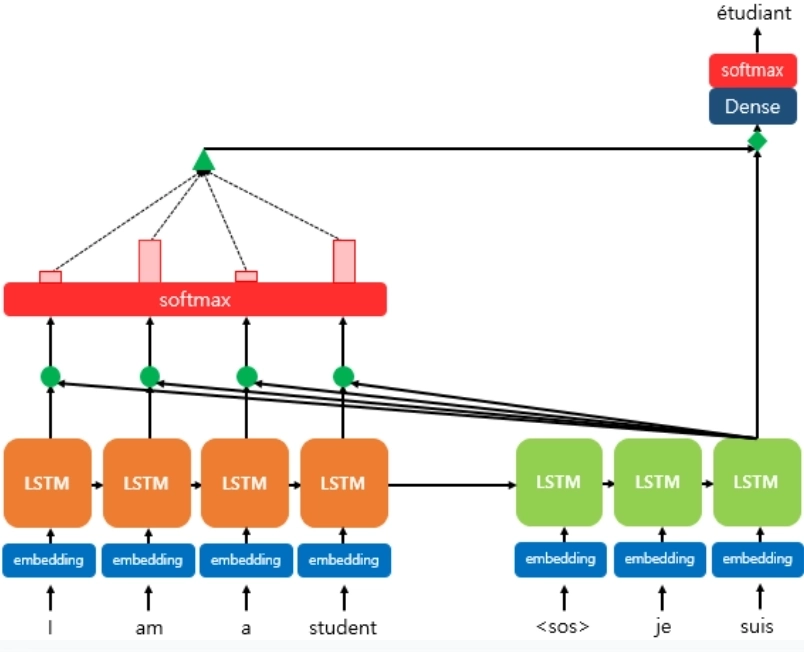  
  
- 기존 Seq2Seq과 달리, 디코더와 인코더의 모든 위치를 직접 비교
- 과정
    1. 입력을 벡터 형태로 변환  
    2. 단어별 중요도 계산
    - 관련도 점수: 현재 작업과 각 단어 사이의 관계가 얼마나 관련이 높고 유사한지 점수 매김
    - Softmax: 관련도 점수를 0~1 사이의 확률값으로 변환
    3. 중요도에 따른 입력 정보 조합
  
- 장점
    - 시간 경과에 대한 유연성: 모든 단어를 직접 비교하므로 거리와 상관없이 관계 파악이 가능
    - 공간에 대한 유연성: 모든 위치를 직접 연결하여 한 번에 전역적인 관계를 학습할 수 있음
- 병렬화: 관련도 계산이 각 단어 쌍마다 독립적이므로 동시에 계산 가능  
  
  
### 1-2. Attention is All You Need  
  
#### Transformer 구조를 처음 발표한 논문  
  
- 배경: RNN, RNN 기반 모델들의 한계
    - 순차적 구조 한계, 병렬 처리 불가능
- Transformer의 등장: **RNN, CNN을 완전히 제거**하고 Self-Attention으로 입력과 출력의 관계를 계산하는 모델
- 파급효과
    - LLM의 탄생
    - NLP 표준 구조로 자리잡음
    - 이미지, 음성등 타 분야로 확장
  
#### Transformer란?  
  
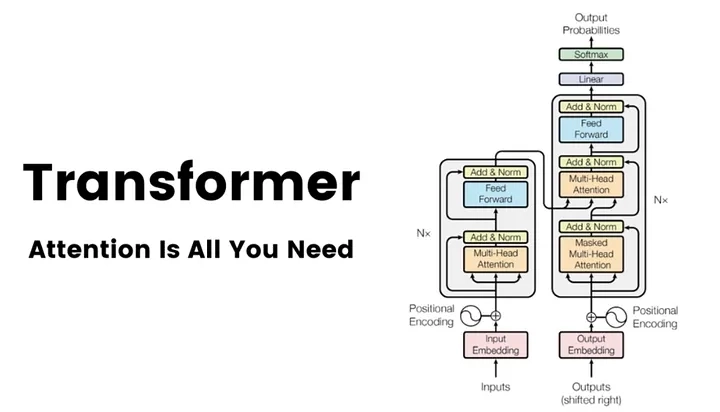  
  
- 정의: RNN처럼 단어를 순서대로 처리하지 않고, Attetnion만으로 문장 전체의 의미와 구조를 파악하여 한 번에 처리하는 인코더-디코더 모델
- 구조: 인코더, 디코더 내부를 LSTM 방식이 아니라 Self-Attention으로 선택하여 단어 순서 정보를 RNN이 순서대로 읽으며 반영하는 것이 아닌, Positional Encoding으로 따로 추가


## 2. Self-Attention  
  
### 2-1. Query, Key, Value  
  
#### Attention의 기본 구조  
  
- RNN의 한계: 장기 의존성 문제 (기울기 소실)
- LSTM의 한계: 순서대로 처리하는 구조 자체는 바꾸지 못함
  
> **Transformer**: 구조 자체를 바꾸어 순서대로 전달하는 대신 모든 단어를 서로 직접 비교  
  
  
#### Q, K, V 개념  
  
> Attention: Query를 Key들과 비교해 관련도를 구하고 그 비율만큼 Value를 섞어 결과를 만드는 계산  
  
- Query: 현재 처리 중인 단어가 다른 단어들에게 "지금 나에게 필요한 정보가 뭔지" 묻는 벡터  
- Key: 검색 대상이 되는 모든 정보의 이름표  
- Value: 실제로 전달하는 정보 벡터
  
  
### 2-2. 기존 Cross Attention vs Self Attention  
  
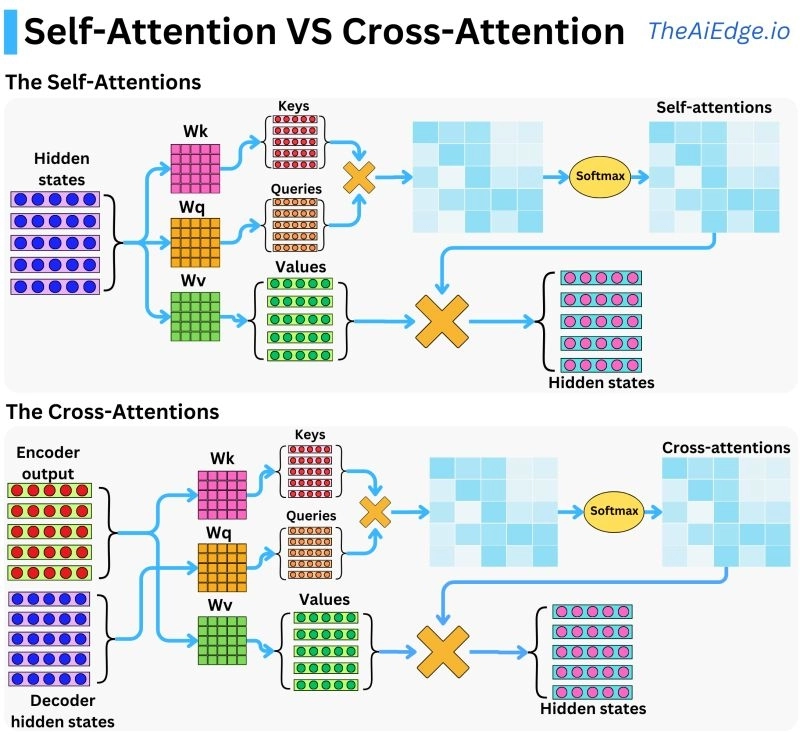  
  
#### Cross-Attention  
  
- Query와 Key-Value 쌍이 서로 다른 시퀀스에서 출력
- 하나의 시퀀스가 독립된 다른 시퀀스를 참고하여 정보를 만들어내는 매커니즘  
- 과정
    1. Query 만들기: 디코더가 현재 상태를 쿼리로 만듦. "다음 단어를 위해 어떤 단어를 봐야할까?"
    2. key, Value 불러오기: 인코더가 원문의 각 단어에 대해 만들어 둔 벡터를 Key 와 Value로 사용
    3. 유사도 계산 (Attention Score): Query와 Key의 관련도를 Softmax로 확률의 값 비율로 변환
    4. Weighted Sum: 비율만큼 Value를 섞어 Context Vector 생성
  
  
#### Self-Attention  
  
- Query와 Key-Value쌍이 같은 시퀀스에서 출력  
- 과정
    1. 벡터 임베딩: 각 단어를 벡터로 변환하고 같은 벡터에서 Q, K, V를 만듦
    2. 내적 및 관련도 점수: 해당 단어의 Query와 모든 단어의 Key를 비교해 관계 점수 계산
    3. 중요도 배분: Softmax & Attention 가중치
    4. 새로운 벡터 생성: 비율만큼 Value를 섞어 문맥을 반영한 새 벡터가 생성
- 위 모든 과정을 동시에 거쳐 각자 문맥이 반영된 새 벡터 얻음 -> 병렬 처리 가능  
  
  
### 2-3. Scaled Dot-Product Attention  
  
#### Dot-Product Attention  
  
- Attention Score를 계산하는 방법 중 하나
    - Query와 Key 벡터를 내적하여 관련도 점수를 구함
    - 내적: 두 벡터의 같은 위치 성분끼리 곱해 모두 더한 값  
        $Q\cdot K = \sum_{i=1}^{d_k} Q_iK_i$
- 과정
    1. Attention Score 계산
    2. 계산된 값에 Softmax 적용 -> Attention Weight 산출
    3. 최종 결과값 계산: Attention Weight * Value
- 문제점: Attention Score 극단화
    - 벡터 차원이 커질수록 내적 값이 지나치게 커질 수 있음. 이러한 극단적인 값이 Softmax 함수에 입력되면 특정 단어에 확률이 과도하게 몰리는 현상 발생 -> 기울기 소실 문제 발생 가능
  
  
#### Scaled Dot-Product Attention  
  
- 기존의 Dot-Product Attention에 스케일링 단계를 추가
- 과정
    1. Query와 Key 내적 -> Attention Score
    2. Attention Score를 $ \sqrt{d_k} $로 나누는 스케일링 진행
    3. Softmax 적용 -> Attention Weight 산출
    4. 최종 결과: ttention Weight * Value
- $ \sqrt{d_k} $로 나누면 분산이 1근처로 돌아와 차원 크기와 상관 없이 점수 안정적  
- Scaled Dot-Product Attention 계산의 결과로 얻어지는 벡터
    - Cross-Attention: Context Vector
    - Self-Atention: 문맥에 맞게 의미가 업데이트된 단어 벡터
    

## 3. Multi-Head Attention  
  
### 3-1. Multi-Head Attention 사용 이유  
  
#### Single-Head Attention vs Multi-Head Attention  
  
- Head: Attention 계산을 한 번 하는 독립된 단위
    - Head마다 가중치 행렬의 숫자가 다르기 때문에 같은 문장을 봐도 집중하는 단어가 달라짐
- Single-Head Attention: Head가 하나. 단어마다 가중치 분포 딱 하나. 여러 정보가 섞여 흐릿해진 벡터 하나가 됨.
- Multi-Head Attention: Attention을 작게 쪼개서 여러 번 동시에 하는 방식. 해드마다 질문 하나에 집중하고 결과를 이어 붙여서 정보끼리 섞이지 않음.
  
  
### 3-2. Multi-Head Attention 작동 방식  
  
#### 전체 흐름 4단계  
  
1. 분할: 8개의 관점 벡터 만들기 (Q, K, V를 세 세트 만듦)  
2. 병렬 어텐션 계산: 각 헤드별 각자 분석. 서로 간섭하지 않고 동시에 Scaled Dot-Product Attention을 계산
3. 이어 붙이기: 8개의 결과를 순서대로 한줄로 이어 붙임
4. 섞기: 이업ㅌ인 벡터에 또 다른 행렬을 곱해 하나의 의미로 융합

## 4. Transforemr 전체 아키텍처  
  
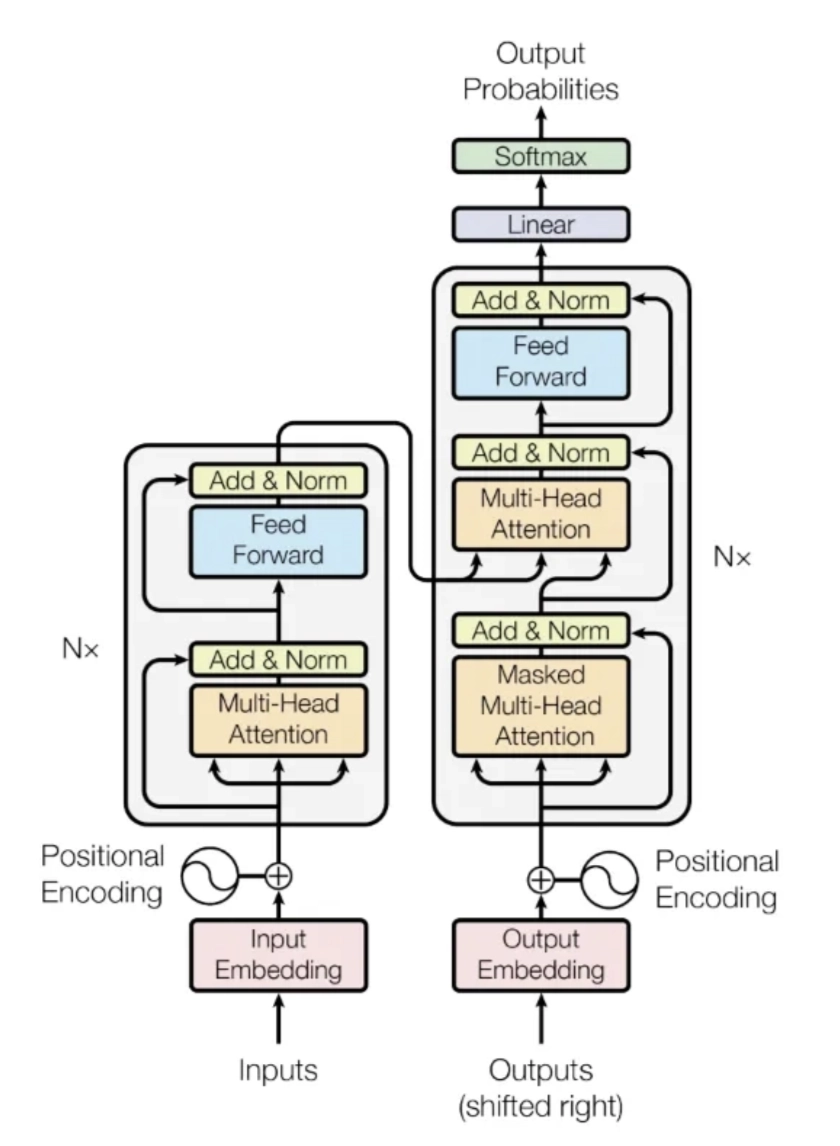  
  
### 4-1. 트랜스포머의 전처리 단계  
  
1. 토큰화: 문장을 모델이 다루는 기본 단위(토큰)로 자름
2. 임베딩: 각 토큰을 벡터로 변환
    - 단어를 공간적 의미로 표현
    - 뜻이 비슷한 단어는 가까운 좌표에 놓임
3. Positional Encoding: 단어들의 순서 정보를 임베딩 벡터에 추가하는 단계  
    - Transformer는 RNN과 달리 모든 단어를 한꺼번에 보기 때문에 순서를 따로 알려줘야 함
    - 각 위치마다 정해진 위치 벡터를 만들어 임베딩에 더함
  

### 4-2. 트랜스포머의 Encoder와 Decoder  
  
1. Encoder: 원문을 깊이 이해하는 분석팀
    - Multi-Head Self-Attention: 원문 단어끼리 서로 보며 문맥 파악
    - Feed-Forward Network: 단어 하나하나를 따로 더 깊이 가공
        - 512차원을 2048차원으로 넓혔다가 다시 512차원으로 좁히는 2층 신경망, 사이에 ReLU 들어감
    - Add & Norm: 모든 부품에 붙는 안전장치
        - Add: Residual Connection. 부품을 통과한 결과에 원래 입력을 그대로 더해줌
        - Norm: Layer Normalization. 한 단어 벡터 안에 숫자를 평균 0, 분산 1 근처로 맞춰줌.
2. Decoder: 번역문을 한 단어씩 쓰는 작성팀
    - Masked Multi-Head Self-Attention: 지금까지 쓴 번역 단어끼리 관계 파악
    - Encoder-Decoder Attention (Cross-Attention): 원문 분석 자료(Encoder 출력)에서 필요한 부분 찾기
        - 출력 문장과 입력 문장을 연결하는 과정
        - Q = 직전 Decoder 서브 레이어의 출ㄺ
        - K, V = Encoder 마지막 층의 출력
    - Feed-Forward Network: Encoder와 동일
    - 세 부품 뒤에도 각각 Add & Norm 붙음
    - 6층을 다 통과하면 Linear + Softmax가 다음 단어의 확률을 계산
    - Masked Multi-Head Attention: Decoder의 Self-Attention에서 미래 시점의 단어 정보를 가려 자기보다 앞의 단어만 보게 함  
  
  
### 4-3. 전체 모델 및 데이터 흐름  
  
- 입력 준비: 문장을 [의미+위치] 벡터로 변환
- 인코더: 입력 문장의 [문맥적 의미] 깊이 이해하기
- 디코더: 번역 문장을 [한 단어씩] 생성하기
